# Exploratory Data Analysis: Singapore HDB Monthly Rent

This notebook explores `data/train.csv` for the CS5228 rental-price regression task.

## Objectives

1. Validate schema, types, missingness, duplicates, and constant columns.
2. Examine the `MONTHLY_RENT` target distribution and unusual observations.
3. Study temporal, location, flat-type, model, floor-area, and lease patterns.
4. Identify preprocessing requirements and leakage-safe validation choices.
5. Finish with concrete modelling recommendations.

All summaries and charts are generated from the CSV when the notebook runs.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "primary": "#2C7FB8",
    "secondary": "#7FCDBB",
    "accent": "#F03B20",
    "neutral": "#636363",
}

# Works when launched from either the repository root or project/.
DATA_PATH = next(
    path for path in (Path("data/train.csv"), Path("project/data/train.csv"))
    if path.exists()
)
df = pd.read_csv(DATA_PATH)

print(f"Loaded {DATA_PATH}: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Loaded data/train.csv: 150,000 rows × 11 columns


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.00,yes,2012,0.00,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.00,yes,2001,0.00,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.00,yes,1976,0.00,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.00,yes,2010,0.00,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.00,yes,2001,0.00,1800


## 1. Dataset structure and data quality

Start with schema, cardinality, missing values, constants, and duplicate records. These checks determine which columns need cleaning before any model is trained.

In [2]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100),
    "n_unique": df.nunique(dropna=False),
}).sort_values(["missing_pct", "n_unique"], ascending=[False, True])

display(schema)
print(f"Date range: {df['RENT_APPROVAL_DATE'].min()} to {df['RENT_APPROVAL_DATE'].max()}")
print(f"Total missing cells: {df.isna().sum().sum():,}")

,dtype,missing,missing_pct,n_unique
FURNISHED,object,0,0.00,1
FEE,float64,0,0.00,1
FLAT_TYPE,object,0,0.00,11
FLAT_MODEL,object,0,0.00,20
TOWN,object,0,0.00,26
RENT_APPROVAL_DATE,object,0,0.00,51
LEASE_COMMENCE_DATE,int64,0,0.00,57
FLOOR_AREA_SQM,float64,0,0.00,156
MONTHLY_RENT,int64,0,0.00,608
STREET,object,0,0.00,1146


Date range: 2021-01 to 2025-03
Total missing cells: 0


In [3]:
feature_columns = df.columns.drop("MONTHLY_RENT").tolist()
quality_summary = pd.Series({
    "rows": len(df),
    "columns": df.shape[1],
    "exact_duplicate_rows": df.duplicated().sum(),
    "duplicate_feature_rows": df.duplicated(feature_columns).sum(),
    "constant_columns": int((df.nunique(dropna=False) == 1).sum()),
}, name="count")
display(quality_summary.to_frame())

constant_columns = df.columns[df.nunique(dropna=False) == 1].tolist()
print("Constant columns:", constant_columns)
print("Constant values:", {column: df[column].iloc[0] for column in constant_columns})

# Multiple rental applications may legitimately share all recorded features,
# so feature-level duplicates are not automatically errors. Exact duplicates
# require investigation before removal because the dataset has no transaction ID.
exact_duplicate_examples = df[df.duplicated(keep=False)].sort_values(feature_columns).head(10)
display(exact_duplicate_examples)

,count
rows,150000
columns,11
exact_duplicate_rows,425
duplicate_feature_rows,15547
constant_columns,2


Constant columns: ['FURNISHED', 'FEE']
Constant values: {'FURNISHED': 'yes', 'FEE': np.float64(0.0)}


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
66012,2022-11,bukit merah,80c,telok blangah street 31,3-room,premium apartment,68.00,yes,2013,0.00,3000
66598,2022-11,bukit merah,80c,telok blangah street 31,3-room,premium apartment,68.00,yes,2013,0.00,3000
86589,2023-06,bukit merah,16,cantonment close,3-room,model a,60.00,yes,2003,0.00,3400
87763,2023-06,bukit merah,16,cantonment close,3-room,model a,60.00,yes,2003,0.00,3400
96976,2023-10,toa payoh,108,potong pasir avenue 1,3-room,model a,74.00,yes,1984,0.00,3500
97553,2023-10,toa payoh,108,potong pasir avenue 1,3-room,model a,74.00,yes,1984,0.00,3500
105073,2023-12,ang mo kio,106,ang mo kio avenue 4,3-room,new generation,74.00,yes,1978,0.00,3000
105681,2023-12,ang mo kio,106,ang mo kio avenue 4,3-room,new generation,74.00,yes,1978,0.00,3000
103027,2023-12,ang mo kio,560,ang mo kio avenue 10,3-room,new generation,82.00,yes,1980,0.00,3000
104070,2023-12,ang mo kio,560,ang mo kio avenue 10,3-room,new generation,82.00,yes,1980,0.00,3000


### Initial data-quality findings

- There are **no missing values** in the raw training data.
- `FURNISHED` is always `yes` and `FEE` is always `0.0`; both have zero predictive variance and should be dropped.
- There are exact duplicate rows. Because there is no transaction identifier, these could be genuine separate applications with identical recorded attributes. Compare validation results with and without exact-duplicate removal rather than deleting them automatically.
- Repeated feature rows with different rent values are plausible: multiple flats or applications can share the same month, address-level attributes, flat type, area, and lease year.

## 2. Target: `MONTHLY_RENT`

Inspect location, spread, skew, extreme values, and whether a logarithmic target transformation is likely to help.

,MONTHLY_RENT
count,"150,000.00"
mean,"2,719.04"
std,749.73
min,300.00
1%,"1,300.00"
5%,"1,650.00"
50%,"2,700.00"
95%,"4,000.00"
99%,"4,600.00"
max,"7,600.00"


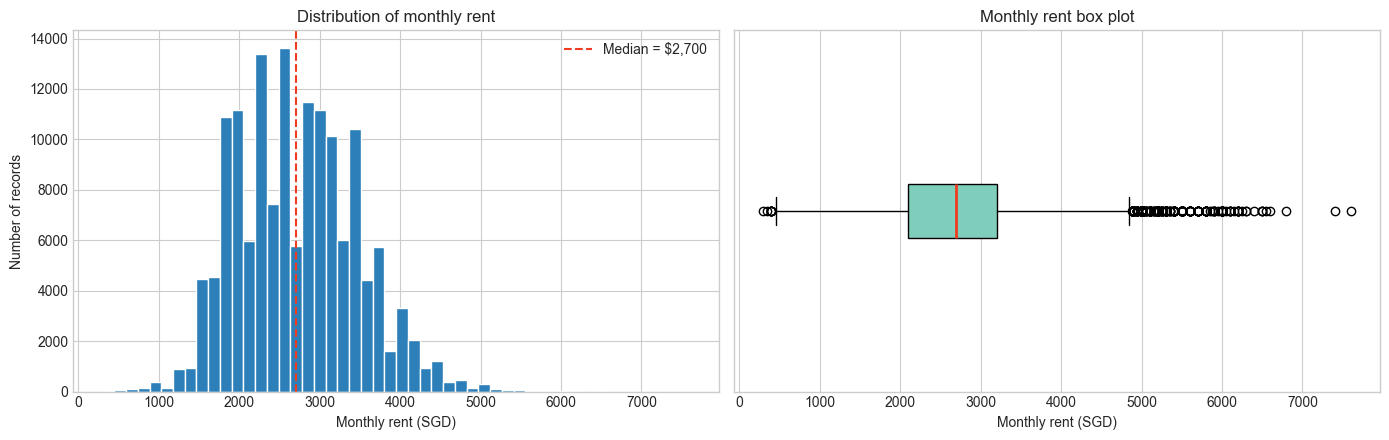

In [4]:
target = df["MONTHLY_RENT"]
q1, q3 = target.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_iqr_outlier = ~target.between(lower_fence, upper_fence)

target_summary = target.describe(percentiles=[0.01, 0.05, 0.95, 0.99]).to_frame("MONTHLY_RENT")
target_summary.loc["skew"] = target.skew()
target_summary.loc["IQR outliers"] = is_iqr_outlier.sum()
target_summary.loc["IQR outlier %"] = is_iqr_outlier.mean() * 100
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(target, bins=50, color=COLORS["primary"], edgecolor="white")
axes[0].axvline(target.median(), color=COLORS["accent"], linestyle="--", label=f"Median = ${target.median():,.0f}")
axes[0].set(title="Distribution of monthly rent", xlabel="Monthly rent (SGD)", ylabel="Number of records")
axes[0].legend()

axes[1].boxplot(target, vert=False, patch_artist=True,
                boxprops={"facecolor": COLORS["secondary"]},
                medianprops={"color": COLORS["accent"], "linewidth": 2})
axes[1].set(title="Monthly rent box plot", xlabel="Monthly rent (SGD)", yticks=[])
plt.tight_layout()
plt.show()

In [5]:
extreme_examples = pd.concat([
    df.nsmallest(8, "MONTHLY_RENT").assign(EXTREME="lowest"),
    df.nlargest(8, "MONTHLY_RENT").assign(EXTREME="highest"),
])
display(extreme_examples[[
    "EXTREME", "RENT_APPROVAL_DATE", "TOWN", "FLAT_TYPE", "FLAT_MODEL",
    "FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTHLY_RENT"
]])

print(f"Rents below $500: {(target < 500).sum():,}")
print(f"Rents above $6,000: {(target > 6_000).sum():,}")

,EXTREME,RENT_APPROVAL_DATE,TOWN,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT
48007,lowest,2022-04,punggol,2-room,model a,46.00,2014,300
24543,lowest,2021-08,central,2 room,improved,54.00,1971,350
9563,lowest,2021-04,sembawang,2 room,model a,46.00,2015,400
26977,lowest,2021-09,sembawang,2 room,model a,46.00,2015,400
44521,lowest,2022-03,sembawang,2-room,model a,46.00,2015,400
47826,lowest,2022-04,woodlands,2-room,improved,45.00,1984,400
81843,lowest,2023-04,jurong west,2-room,model a,37.00,1978,400
142876,lowest,2025-01,hougang,2-room,model a,38.00,2019,400
101586,highest,2023-11,central,5-room,adjoined flat,129.00,1977,7600
96685,highest,2023-09,geylang,5-room,improved,113.00,2000,7400


Rents below $500: 12
Rents above $6,000: 24


### Target findings

The rent distribution is only mildly right-skewed, so predicting raw SGD rent is reasonable. The IQR rule flags roughly 0.5% of records, but large rents are often associated with large or unusual flats in central locations. Very low rents may reflect partial-flat/room rentals or recording anomalies not represented by a separate feature. Do not remove target extremes solely from a box-plot rule; inspect model residuals and validate any filtering decision.

## 3. Time trend and potential distribution shift

Rental approval month is likely one of the strongest predictors. Since the competition test period follows the training period, the validation strategy must preserve chronology.

,records,mean_rent,median_rent
RENT_YEAR,,,
2021,37619,"2,121.14","2,100.00"
2022,32564,"2,524.06","2,450.00"
2023,35654,"3,035.90","3,000.00"
2024,35239,"3,109.67","3,100.00"
2025,8924,"3,142.46","3,150.00"


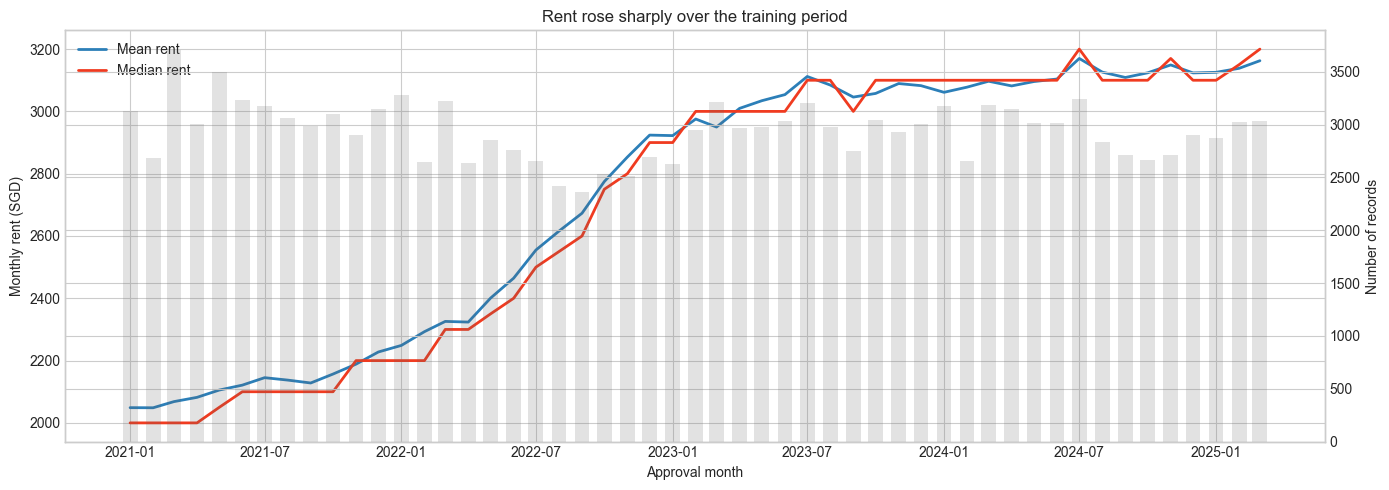

Average of first six monthly means: $2,079
Average of last six monthly means:  $3,137 (50.9% higher)


In [6]:
eda = df.copy()
eda["RENT_DATE"] = pd.to_datetime(eda["RENT_APPROVAL_DATE"], format="%Y-%m")
eda["RENT_YEAR"] = eda["RENT_DATE"].dt.year
eda["RENT_MONTH"] = eda["RENT_DATE"].dt.month
eda["MONTH_INDEX"] = (
    (eda["RENT_YEAR"] - eda["RENT_YEAR"].min()) * 12
    + eda["RENT_MONTH"] - eda["RENT_MONTH"].min()
)

monthly = (
    eda.groupby("RENT_DATE")
    .agg(records=("MONTHLY_RENT", "size"), mean_rent=("MONTHLY_RENT", "mean"), median_rent=("MONTHLY_RENT", "median"))
    .reset_index()
)

yearly = (
    eda.groupby("RENT_YEAR")
    .agg(records=("MONTHLY_RENT", "size"), mean_rent=("MONTHLY_RENT", "mean"), median_rent=("MONTHLY_RENT", "median"))
)
display(yearly)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly["RENT_DATE"], monthly["mean_rent"], color=COLORS["primary"], linewidth=2, label="Mean rent")
ax1.plot(monthly["RENT_DATE"], monthly["median_rent"], color=COLORS["accent"], linewidth=2, label="Median rent")
ax1.set(xlabel="Approval month", ylabel="Monthly rent (SGD)", title="Rent rose sharply over the training period")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.bar(monthly["RENT_DATE"], monthly["records"], width=20, alpha=0.18, color=COLORS["neutral"], label="Records")
ax2.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

first_six = monthly.head(6)["mean_rent"].mean()
last_six = monthly.tail(6)["mean_rent"].mean()
print(f"Average of first six monthly means: ${first_six:,.0f}")
print(f"Average of last six monthly means:  ${last_six:,.0f} ({(last_six / first_six - 1):.1%} higher)")

### Temporal finding

Mean rent increased from about **$2.1k** in the first six training months to about **$3.1k** in the last six. A random train/validation split would leak future market levels into validation and produce an optimistic score. Use expanding-window or blocked temporal validation, with the latest training months as validation. Encode time as year/month plus a continuous month index; tree models can use these directly.

## 4. Categorical consistency and cardinality

Check frequency, rare levels, and formatting drift. In particular, inspect whether categories changed representation over time.

In [7]:
categorical_columns = [
    "TOWN", "BLOCK", "STREET", "FLAT_TYPE", "FLAT_MODEL", "FURNISHED"
]
cardinality = pd.DataFrame({
    "n_unique_raw": df[categorical_columns].nunique(),
    "most_common": [df[c].mode().iat[0] for c in categorical_columns],
    "most_common_count": [df[c].value_counts().iat[0] for c in categorical_columns],
})
display(cardinality)

flat_type_style_by_year = pd.crosstab(
    eda["RENT_YEAR"],
    np.where(eda["FLAT_TYPE"].str.contains("-"), "hyphen", "space/no-hyphen"),
)
display(flat_type_style_by_year)

raw_to_clean = (
    eda.assign(FLAT_TYPE_CLEAN=eda["FLAT_TYPE"].str.lower().str.replace(" room", "-room", regex=False))
    .groupby(["FLAT_TYPE", "FLAT_TYPE_CLEAN"])
    .size()
    .rename("records")
    .reset_index()
    .sort_values(["FLAT_TYPE_CLEAN", "FLAT_TYPE"])
)
display(raw_to_clean)

,n_unique_raw,most_common,most_common_count
TOWN,26,jurong west,10482
BLOCK,2720,2,921
STREET,1146,ang mo kio avenue 3,1590
FLAT_TYPE,11,4-room,40688
FLAT_MODEL,20,improved,44008
FURNISHED,1,yes,150000


col_0,hyphen,space/no-hyphen
RENT_YEAR,,
2021,0,37619
2022,30795,1769
2023,33721,1933
2024,33457,1782
2025,8462,462


,FLAT_TYPE,FLAT_TYPE_CLEAN,records
0,1 room,1-room,8
1,1-room,1-room,34
2,2 room,2-room,532
3,2-room,2-room,2566
4,3 room,3-room,12092
5,3-room,3-room,36932
6,4 room,4-room,13391
7,4-room,4-room,40688
8,5 room,5-room,9308
9,5-room,5-room,26215


,raw_unique,clean_unique
FLAT_TYPE,11,6
STREET,1146,576


,records,mean_area,mean_rent,median_rent
FLAT_TYPE_CLEAN,,,,
1-room,42,31.00,"1,498.21","1,450.00"
2-room,3098,45.67,"1,979.52","2,100.00"
3-room,49024,67.97,"2,386.55","2,350.00"
4-room,54079,95.53,"2,837.88","2,800.00"
5-room,35523,117.81,"2,981.71","3,000.00"
executive,8234,142.72,"3,069.33","3,000.00"


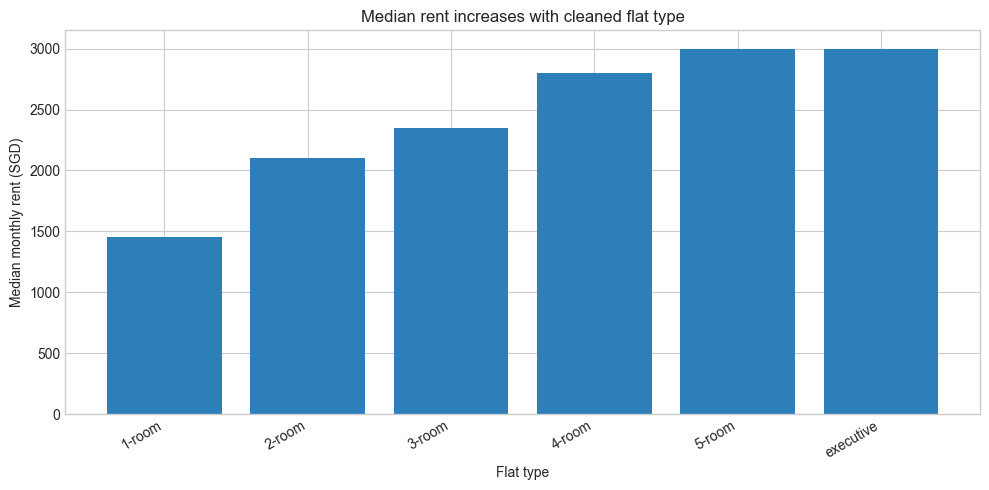

In [8]:
eda["FLAT_TYPE_CLEAN"] = (
    eda["FLAT_TYPE"]
    .str.strip()
    .str.lower()
    .str.replace(" room", "-room", regex=False)
)
eda["STREET_CLEAN"] = eda["STREET"].str.strip().str.lower()

cleaning_effect = pd.DataFrame({
    "raw_unique": [df["FLAT_TYPE"].nunique(), df["STREET"].nunique()],
    "clean_unique": [eda["FLAT_TYPE_CLEAN"].nunique(), eda["STREET_CLEAN"].nunique()],
}, index=["FLAT_TYPE", "STREET"])
display(cleaning_effect)

flat_type_summary = (
    eda.groupby("FLAT_TYPE_CLEAN")
    .agg(records=("MONTHLY_RENT", "size"), mean_area=("FLOOR_AREA_SQM", "mean"),
         mean_rent=("MONTHLY_RENT", "mean"), median_rent=("MONTHLY_RENT", "median"))
    .sort_values("mean_area")
)
display(flat_type_summary)

fig, ax = plt.subplots(figsize=(10, 5))
order = flat_type_summary.index
ax.bar(order, flat_type_summary["median_rent"], color=COLORS["primary"])
ax.set(title="Median rent increases with cleaned flat type", xlabel="Flat type", ylabel="Median monthly rent (SGD)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Category finding: a hidden time proxy

`FLAT_TYPE` uses spaces throughout 2021 (`4 room`) and mostly hyphens from 2022 onward (`4-room`). Their areas are nearly identical, so they are formatting variants—not different flat types. Leaving them separate lets a model use spelling as a proxy for year and exaggerates category effects. Normalize them before EDA/model fitting. Lowercasing `STREET` also reduces its apparent cardinality substantially.

## 5. Location effects

Town comparisons are confounded by flat size, flat type, and month. The charts below are descriptive rather than causal, but they show why granular location features are needed.

,records,mean_area,median_rent,median_rent_per_sqm
TOWN,,,,
central,2278,75.29,"3,000.00",41.10
queenstown,6115,77.13,"2,900.00",38.18
bukit merah,8270,84.15,"2,900.00",35.59
marine parade,1637,79.14,"2,600.00",34.09
clementi,5429,81.68,"2,700.00",34.09
kallang/whampoa,5689,81.90,"2,700.00",33.98
toa payoh,5988,80.82,"2,600.00",32.82
geylang,4504,79.07,"2,500.00",32.49
bukit timah,438,99.35,"3,000.00",31.51


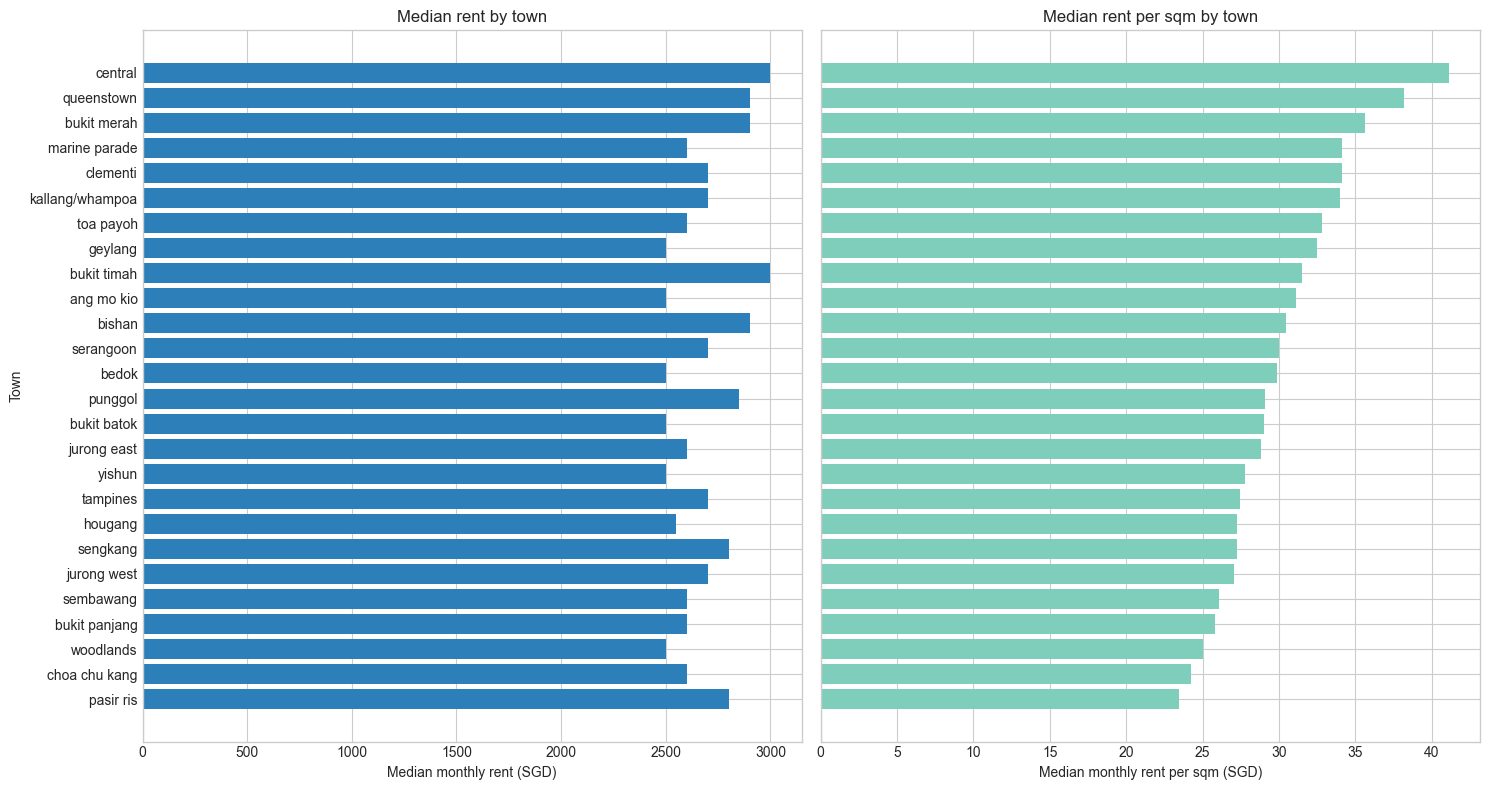

In [9]:
eda["RENT_PER_SQM"] = eda["MONTHLY_RENT"] / eda["FLOOR_AREA_SQM"]
town_summary = (
    eda.groupby("TOWN")
    .agg(records=("MONTHLY_RENT", "size"), mean_area=("FLOOR_AREA_SQM", "mean"),
         median_rent=("MONTHLY_RENT", "median"), median_rent_per_sqm=("RENT_PER_SQM", "median"))
    .sort_values("median_rent_per_sqm")
)
display(town_summary.sort_values("median_rent_per_sqm", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
axes[0].barh(town_summary.index, town_summary["median_rent"], color=COLORS["primary"])
axes[0].set(title="Median rent by town", xlabel="Median monthly rent (SGD)", ylabel="Town")
axes[1].barh(town_summary.index, town_summary["median_rent_per_sqm"], color=COLORS["secondary"])
axes[1].set(title="Median rent per sqm by town", xlabel="Median monthly rent per sqm (SGD)")
plt.tight_layout()
plt.show()

FLAT_TYPE_CLEAN,3-room,4-room,5-room
TOWN,,,
central,"2,600.00","3,500.00","4,650.00"
queenstown,"2,500.00","3,500.00","3,600.00"
bukit merah,"2,500.00","3,250.00","3,500.00"
clementi,"2,500.00","3,100.00","3,300.00"
punggol,"2,700.00","3,000.00","3,000.00"
bishan,"2,500.00","3,000.00","3,200.00"
toa payoh,"2,300.00","3,000.00","3,225.00"
kallang/whampoa,"2,400.00","3,000.00","3,200.00"
marine parade,"2,400.00","3,000.00","3,300.00"


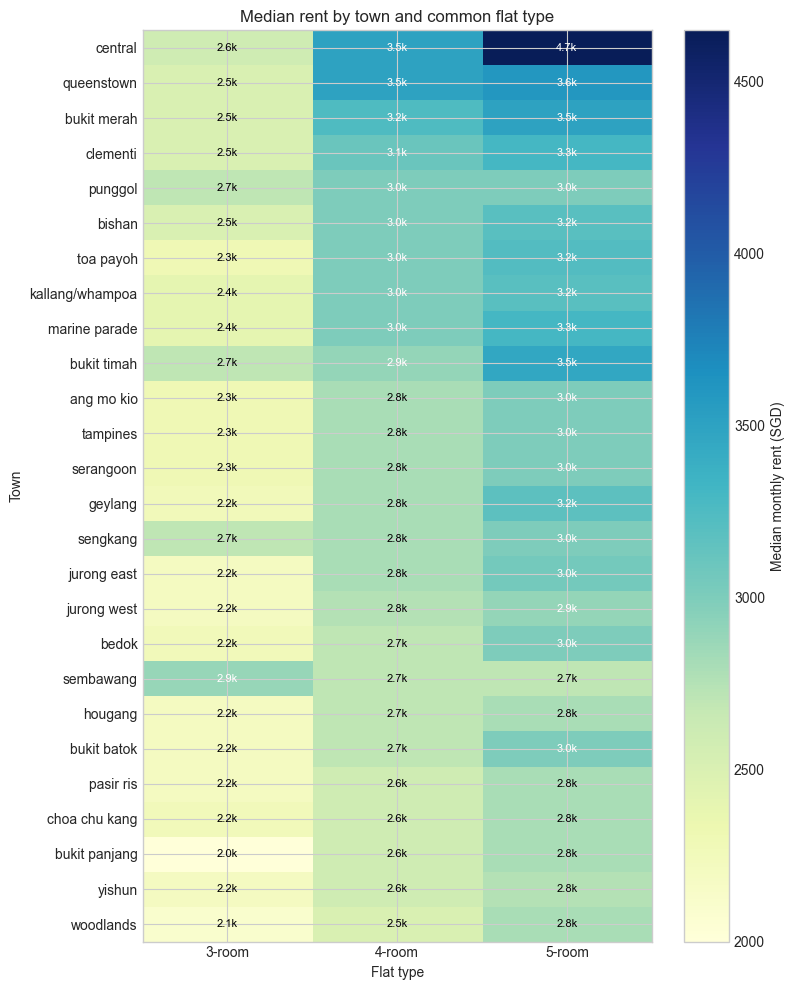

In [10]:
town_type_median = eda.pivot_table(
    index="TOWN",
    columns="FLAT_TYPE_CLEAN",
    values="MONTHLY_RENT",
    aggfunc="median",
)
common_types = ["3-room", "4-room", "5-room"]
heatmap_data = town_type_median[common_types].sort_values("4-room", ascending=False)

display(heatmap_data)

fig, ax = plt.subplots(figsize=(8, 10))
image = ax.imshow(heatmap_data, aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(len(common_types)), labels=common_types)
ax.set_yticks(range(len(heatmap_data.index)), labels=heatmap_data.index)
ax.set(title="Median rent by town and common flat type", xlabel="Flat type", ylabel="Town")
for row in range(heatmap_data.shape[0]):
    for col in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value/1000:.1f}k", ha="center", va="center", fontsize=8,
                    color="white" if value > np.nanmedian(heatmap_data.values) else "black")
fig.colorbar(image, ax=ax, label="Median monthly rent (SGD)")
plt.tight_layout()
plt.show()

## 6. Floor area, lease age, and flat model

Measure numeric relationships with rent and check whether rare flat models create unstable category estimates.

,count,mean,std,min,25%,50%,75%,max
FLOOR_AREA_SQM,"150,000.00",93.34,24.27,31.00,68.00,92.00,110.00,215.00
LEASE_COMMENCE_DATE,"150,000.00","1,990.91",12.64,"1,966.00","1,981.00","1,988.00","2,001.00","2,022.00"
FLAT_AGE_AT_RENT,"150,000.00",31.73,12.65,-1.00,22.00,34.00,42.00,59.00
APPROX_REMAINING_LEASE,"150,000.00",67.27,12.65,40.00,57.00,65.00,77.00,100.00
MONTHLY_RENT,"150,000.00","2,719.04",749.73,300.00,"2,100.00","2,700.00","3,200.00","7,600.00"
RENT_PER_SQM,"150,000.00",30.48,9.54,4.26,23.33,29.51,36.44,87.50


,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,FLAT_AGE_AT_RENT,APPROX_REMAINING_LEASE,MONTH_INDEX,MONTHLY_RENT
FLOOR_AREA_SQM,1.00,0.34,-0.34,0.34,-0.03,0.33
LEASE_COMMENCE_DATE,0.34,1.00,-0.99,0.99,0.04,0.23
FLAT_AGE_AT_RENT,-0.34,-0.99,1.00,-1.00,0.05,-0.18
APPROX_REMAINING_LEASE,0.34,0.99,-1.00,1.00,-0.05,0.18
MONTH_INDEX,-0.03,0.04,0.05,-0.05,1.00,0.54
MONTHLY_RENT,0.33,0.23,-0.18,0.18,0.54,1.00


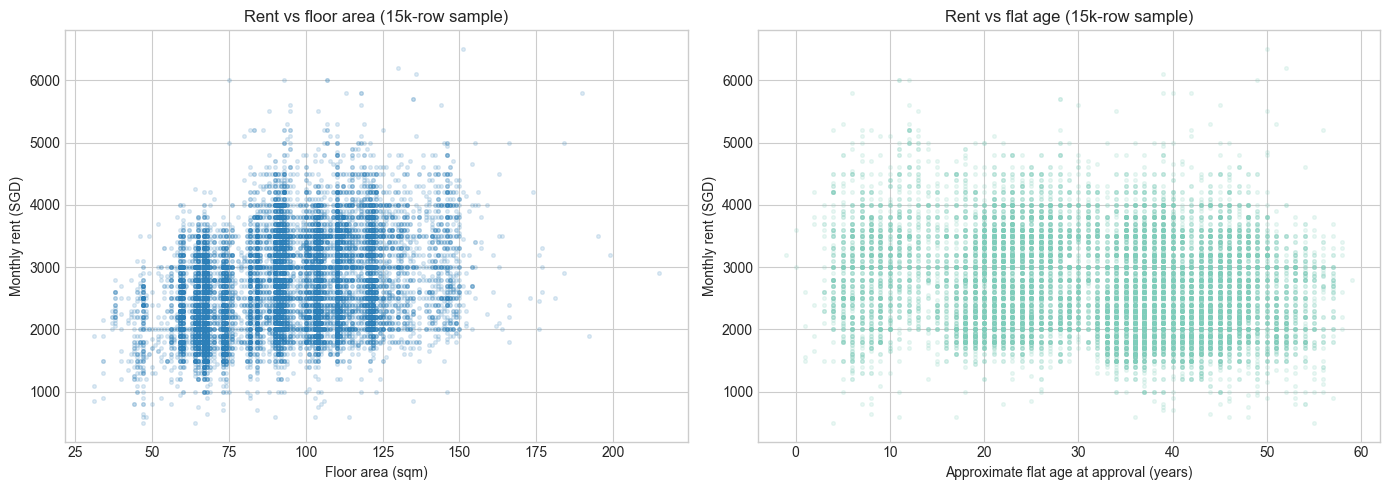

In [11]:
eda["FLAT_AGE_AT_RENT"] = eda["RENT_YEAR"] - eda["LEASE_COMMENCE_DATE"]
eda["APPROX_REMAINING_LEASE"] = 99 - eda["FLAT_AGE_AT_RENT"]

numeric_summary = eda[[
    "FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "FLAT_AGE_AT_RENT",
    "APPROX_REMAINING_LEASE", "MONTHLY_RENT", "RENT_PER_SQM"
]].describe().T
display(numeric_summary)

display(eda[[
    "FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "FLAT_AGE_AT_RENT",
    "APPROX_REMAINING_LEASE", "MONTH_INDEX", "MONTHLY_RENT"
]].corr().round(3))

sample = eda.sample(min(15_000, len(eda)), random_state=5228)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(sample["FLOOR_AREA_SQM"], sample["MONTHLY_RENT"], s=7, alpha=0.15, color=COLORS["primary"])
axes[0].set(title="Rent vs floor area (15k-row sample)", xlabel="Floor area (sqm)", ylabel="Monthly rent (SGD)")
axes[1].scatter(sample["FLAT_AGE_AT_RENT"], sample["MONTHLY_RENT"], s=7, alpha=0.15, color=COLORS["secondary"])
axes[1].set(title="Rent vs flat age (15k-row sample)", xlabel="Approximate flat age at approval (years)", ylabel="Monthly rent (SGD)")
plt.tight_layout()
plt.show()

,records,mean_area,median_rent
FLAT_MODEL,,,
improved,44008,96.84,"2,700.00"
model a,42745,93.12,"2,700.00"
new generation,27380,77.26,"2,450.00"
premium apartment,12312,105.69,"2,900.00"
simplified,6794,77.69,"2,500.00"
standard,5903,74.28,"2,500.00"
apartment,4724,142.06,"3,000.00"
maisonette,2346,147.80,"3,000.00"
model a2,1553,89.09,"2,550.00"


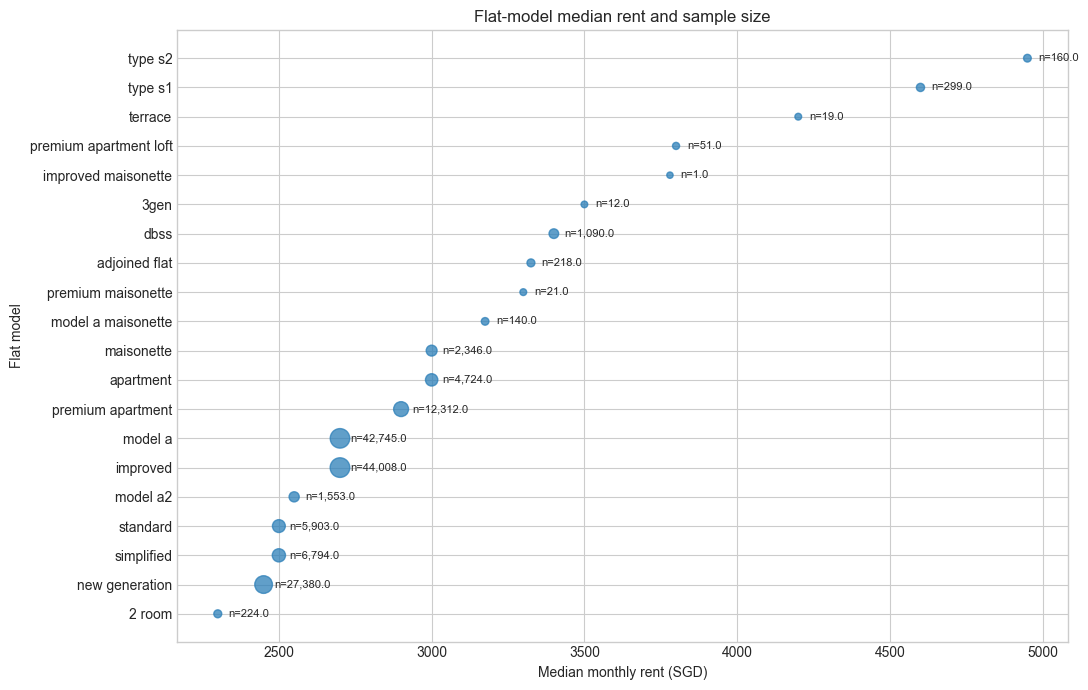

Models with fewer than 100 records:


,records,mean_area,median_rent
FLAT_MODEL,,,
premium apartment loft,51,103.67,"3,800.00"
premium maisonette,21,157.52,"3,300.00"
terrace,19,91.77,"4,200.00"
3gen,12,120.50,"3,500.00"
improved maisonette,1,137.00,"3,780.00"


In [12]:
model_summary = (
    eda.groupby("FLAT_MODEL")
    .agg(records=("MONTHLY_RENT", "size"), mean_area=("FLOOR_AREA_SQM", "mean"), median_rent=("MONTHLY_RENT", "median"))
    .sort_values("records", ascending=False)
)
display(model_summary)

fig, ax = plt.subplots(figsize=(11, 7))
plot_data = model_summary.sort_values("median_rent")
point_sizes = 20 + 180 * np.sqrt(plot_data["records"] / plot_data["records"].max())
ax.scatter(plot_data["median_rent"], plot_data.index, s=point_sizes, color=COLORS["primary"], alpha=0.75)
ax.set(title="Flat-model median rent and sample size", xlabel="Median monthly rent (SGD)", ylabel="Flat model")
for model, row in plot_data.iterrows():
    ax.text(row["median_rent"] + 35, model, f"n={row['records']:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

print("Models with fewer than 100 records:")
display(model_summary[model_summary["records"] < 100])

### Numeric and model findings

- Floor area has a moderate positive relationship with total rent, but it is strongly tied to flat type; use both.
- Newer lease commencement dates show a positive raw relationship with rent, but time and location confound it. `FLAT_AGE_AT_RENT = approval year − lease commencement year` is easier to interpret.
- Several flat models have very small samples. One-hot encoding may overfit rare categories; CatBoost-style categorical handling, target encoding performed strictly within training folds, or combining very rare models into `other` are alternatives.
- Rent per sqm is useful for interpretation, not as an input feature, because it directly contains the target and would leak it.

## 7. Interactions and robustness checks

A useful predictor must explain variation beyond the overall time trend. Compare common flat types over time and inspect within-type area ranges before labelling large areas as errors.

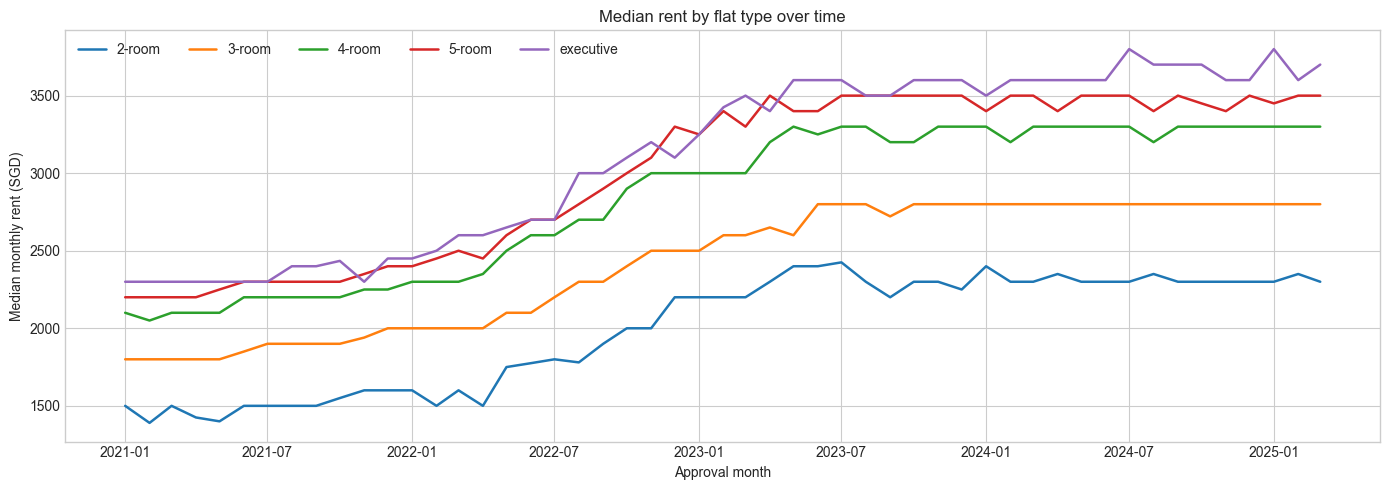

,count,mean,std,min,25%,50%,75%,max
FLAT_TYPE_CLEAN,,,,,,,,
1-room,42.00,31.00,0.00,31.00,31.00,31.00,31.00,31.00
2-room,"3,098.00",45.67,3.99,34.00,45.00,47.00,47.00,67.00
3-room,"49,024.00",67.97,6.11,52.00,65.00,67.00,72.00,126.40
4-room,"54,079.00",95.53,8.01,70.00,90.00,93.00,103.00,145.00
5-room,"35,523.00",117.81,7.24,99.00,110.00,118.00,122.00,157.00
executive,"8,234.00",142.72,9.75,125.00,137.00,144.00,147.00,215.00


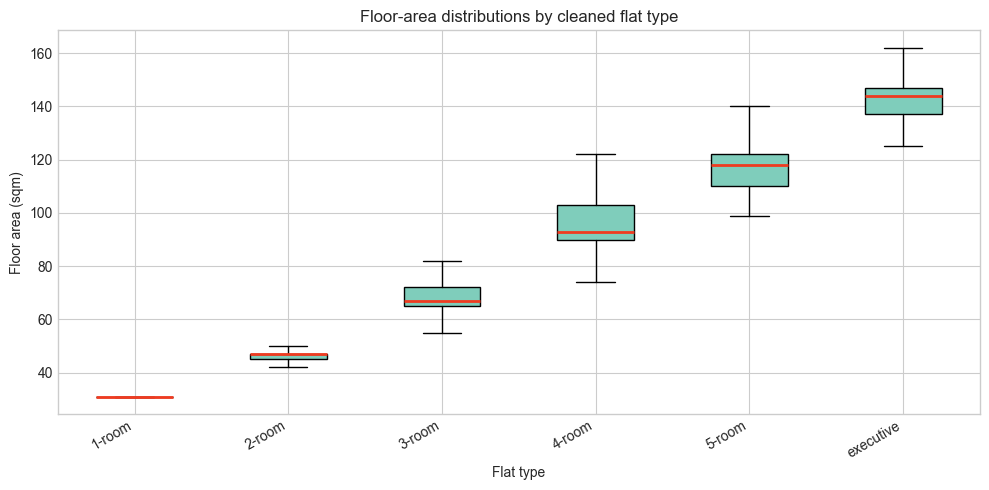

In [13]:
type_month = (
    eda[eda["FLAT_TYPE_CLEAN"].isin(["2-room", "3-room", "4-room", "5-room", "executive"])]
    .groupby(["RENT_DATE", "FLAT_TYPE_CLEAN"])["MONTHLY_RENT"]
    .median()
    .unstack()
)

fig, ax = plt.subplots(figsize=(14, 5))
for column in type_month.columns:
    ax.plot(type_month.index, type_month[column], linewidth=1.8, label=column)
ax.set(title="Median rent by flat type over time", xlabel="Approval month", ylabel="Median monthly rent (SGD)")
ax.legend(ncol=5, loc="upper left")
plt.tight_layout()
plt.show()

area_by_type = eda.groupby("FLAT_TYPE_CLEAN")["FLOOR_AREA_SQM"].describe()
display(area_by_type)

fig, ax = plt.subplots(figsize=(10, 5))
ordered_types = area_by_type.sort_values("50%").index
ax.boxplot(
    [eda.loc[eda["FLAT_TYPE_CLEAN"] == flat_type, "FLOOR_AREA_SQM"] for flat_type in ordered_types],
    labels=ordered_types,
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": COLORS["secondary"]},
    medianprops={"color": COLORS["accent"], "linewidth": 2},
)
ax.set(title="Floor-area distributions by cleaned flat type", xlabel="Flat type", ylabel="Floor area (sqm)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 8. Conclusions and preprocessing plan

### Main findings

1. **Time dominates:** market rent rose substantially from 2021 to early 2025. Validation must be chronological.
2. **Location matters:** town-level rent and rent-per-sqm differ widely. The auxiliary HDB coordinates and MRT distances should add useful detail beyond town/street labels.
3. **Size matters:** floor area and flat type are important but correlated; retain both for nonlinear models.
4. **Category drift exists:** space-form flat types belong mostly to 2021, while hyphenated labels dominate later years. Normalize before modelling.
5. **Raw completeness is high:** no missing cells, but `FURNISHED` and `FEE` are constants.
6. **Extremes need context:** rare low/high rents and unusually large flats are not automatically invalid.
7. **Duplicate handling is uncertain:** exact duplicates exist, but no transaction ID is available. Treat removal as an experiment.

### Recommended preprocessing

- Parse `RENT_APPROVAL_DATE`; derive `RENT_YEAR`, `RENT_MONTH`, and monotonic `MONTH_INDEX`.
- Normalize string whitespace/case; map `"4 room"` and `"4-room"` to the same `FLAT_TYPE` (similarly for 1/2/3/5-room).
- Drop constant `FURNISHED` and `FEE`.
- Derive `FLAT_AGE_AT_RENT`; avoid keeping both this and approximate remaining lease in linear models because they are redundant.
- Keep `TOWN`, normalized `STREET`, `BLOCK`, `FLAT_MODEL`, `FLAT_TYPE`, and `FLOOR_AREA_SQM`.
- Join HDB block metadata and spatial amenity features only after the train-only EDA stage.
- Fit preprocessing inside each validation fold. Any target/frequency encoding must be trained only on the fold's training period.

### Validation design

Use one or more blocked temporal splits, for example:

- Train through 2023-06; validate 2023-07 to 2023-12.
- Train through 2023-12; validate 2024-01 to 2024-06.
- Train through 2024-06; validate 2024-07 to 2025-03.

Report RMSE for each period and compare with a simple baseline such as the training-period median rent by cleaned flat type and town. This tests the model under the future-period shift that the competition test set presents.

In [14]:
# Reproducible modelling-ready view (train only; auxiliary joins are intentionally excluded).
model_df = df.copy()
model_df["RENT_DATE"] = pd.to_datetime(model_df["RENT_APPROVAL_DATE"], format="%Y-%m")
model_df["RENT_YEAR"] = model_df["RENT_DATE"].dt.year
model_df["RENT_MONTH"] = model_df["RENT_DATE"].dt.month
model_df["MONTH_INDEX"] = (
    (model_df["RENT_YEAR"] - model_df["RENT_YEAR"].min()) * 12
    + model_df["RENT_MONTH"] - model_df["RENT_MONTH"].min()
)
model_df["FLAT_TYPE"] = (
    model_df["FLAT_TYPE"].str.strip().str.lower().str.replace(" room", "-room", regex=False)
)
for column in ["TOWN", "BLOCK", "STREET", "FLAT_MODEL"]:
    model_df[column] = model_df[column].astype(str).str.strip().str.lower()
model_df["FLAT_AGE_AT_RENT"] = model_df["RENT_YEAR"] - model_df["LEASE_COMMENCE_DATE"]
model_df = model_df.drop(columns=["FURNISHED", "FEE"])

assert model_df.isna().sum().sum() == 0
assert model_df["FLAT_TYPE"].nunique() == 6
assert all(model_df[column].nunique() > 1 for column in model_df.columns)

print(f"Prepared shape: {model_df.shape[0]:,} rows × {model_df.shape[1]} columns")
model_df.head()

Prepared shape: 150,000 rows × 14 columns


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT,RENT_DATE,RENT_YEAR,RENT_MONTH,MONTH_INDEX,FLAT_AGE_AT_RENT
0,2021-01,punggol,604a,punggol road,4-room,model a,93.00,2012,1800,2021-01-01,2021,1,0,9
1,2021-01,sengkang,290c,compassvale crescent,5-room,improved,110.00,2001,2000,2021-01-01,2021,1,0,20
2,2021-01,queenstown,5,ghim moh road,3-room,improved,65.00,1976,2000,2021-01-01,2021,1,0,45
3,2021-01,sengkang,436b,fernvale road,4-room,model a,96.00,2010,1400,2021-01-01,2021,1,0,11
4,2021-01,sembawang,467b,admiralty drive,4-room,premium apartment,102.00,2001,1800,2021-01-01,2021,1,0,20
